In [1]:
from gas.gas_circuit import GAS_dicke, bin_to_int

In [2]:
import numpy as np 
import json
import os 
import h5py

from qiskit_aer import StatevectorSimulator

from symmer.operators.base import PauliwordOp, QuantumState

from qiskit_aer.primitives import SamplerV2

In [3]:
import h5py

with h5py.File("OH_data.h5", "r") as infile:

    f_op = PauliwordOp(infile["F_true_symp_matrix"][()],
                       infile["F_true_coeff_vec"][()])

    f_op_rounded = PauliwordOp(infile["F_rounded_symp_matrix"][()],
                                infile["F_rounded_coeff_vec"][()])
    
    linear_true = dict(zip(infile["lin_true_keys"][()],
                       infile["lin_true_values"][()]))
    
    quad_true = dict(zip( [(a,b) for a,b in infile["quad_true_keys"][()]],
                       infile["quad_true_values"][()]))
    

    linear_rounded = dict(zip(infile["lin_rounded_keys"][()],
                    infile["lin_rounded_values"][()]))
    
    quad_rounded   = dict(zip([(a,b) for a,b in infile["quad_rounded_keys"][()]],
                         infile["quad_rounded_values"][()]))
    
    n_elec = infile["nelec_cas"][()]
    basis_set = infile["SCF_basis"][()]
    n_spin = 2*infile["ncas"][()]
    pyscf_soln = infile["SCF_e_tot"][()]

    hf_pyscf_psi = QuantumState(infile["hf_subspace_state_matrix"][()], infile["hf_subspace_coeff_vec"][()])


print("LOADED")

LOADED


In [4]:
### write QUBO problem!

from sympy import var
variables = [var(f'x{q_idx}', bool=True) for q_idx in range(n_spin)]

problem_fn = 0
for q_idx, coeff in linear_rounded.items():
    problem_fn+= variables[q_idx]*coeff

for (q_idx1, q_idx2), coeff in quad_rounded.items():
    problem_fn+= variables[q_idx1]*variables[q_idx2]*coeff

problem_fn

80.0*x0*x1 + 48.0*x0*x10 + 64.0*x0*x11 + 68.0*x0*x2 + 72.0*x0*x3 + 16.0*x0*x4 + 16.0*x0*x5 + 64.0*x0*x6 + 68.0*x0*x7 + 56.0*x0*x8 + 56.0*x0*x9 - 294.0*x0 + 64.0*x1*x10 + 48.0*x1*x11 + 72.0*x1*x2 + 68.0*x1*x3 + 16.0*x1*x4 + 16.0*x1*x5 + 68.0*x1*x6 + 64.0*x1*x7 + 56.0*x1*x8 + 56.0*x1*x9 - 294.0*x1 + 56.0*x10*x11 + 56.0*x10*x2 + 60.0*x10*x3 + 16.0*x10*x4 + 16.0*x10*x5 + 56.0*x10*x6 + 56.0*x10*x7 + 48.0*x10*x8 + 48.0*x10*x9 - 136.0*x10 + 60.0*x11*x2 + 56.0*x11*x3 + 16.0*x11*x4 + 16.0*x11*x5 + 56.0*x11*x6 + 56.0*x11*x7 + 48.0*x11*x8 + 48.0*x11*x9 - 136.0*x11 + 80.0*x2*x3 + 16.0*x2*x4 + 20.0*x2*x5 + 64.0*x2*x6 + 68.0*x2*x7 + 48.0*x2*x8 + 60.0*x2*x9 - 296.0*x2 + 20.0*x3*x4 + 16.0*x3*x5 + 68.0*x3*x6 + 64.0*x3*x7 + 60.0*x3*x8 + 48.0*x3*x9 - 296.0*x3 + 52.0*x4*x5 + 16.0*x4*x6 + 16.0*x4*x7 + 20.0*x4*x8 + 20.0*x4*x9 - 114.0*x4 + 16.0*x5*x6 + 16.0*x5*x7 + 20.0*x5*x8 + 20.0*x5*x9 - 114.0*x5 + 68.0*x6*x7 + 52.0*x6*x8 + 52.0*x6*x9 - 278.0*x6 + 52.0*x7*x8 + 52.0*x7*x9 - 278.0*x7 + 52.0*x8*x9 - 132.0*x8

In [5]:
from itertools import combinations
def n_choose_k_vectors(n: int, k: int):
    return np.array(
        [
            [int(i in comb) for i in range(n)]
            for comb in combinations(np.arange(n), k)
        ]
    )

alph_bitstrings = n_choose_k_vectors(f_op.n_qubits//2, n_elec[0])
beta_bitstrings = n_choose_k_vectors(f_op.n_qubits//2, n_elec[1])

eigvals_counter = dict()
for alpha_term in alph_bitstrings:
    for beta_term in beta_bitstrings:
        state = np.vstack((alpha_term, beta_term)).T.reshape([f_op.n_qubits]) 
        evaluated = int(problem_fn.subs(zip(variables, state)))
        
        eigvals_counter[evaluated] = eigvals_counter.get(evaluated, 0) + 1

eigvals_counter, min(eigvals_counter.keys())

({-780: 2,
  -784: 4,
  -678: 10,
  -786: 6,
  -660: 4,
  -672: 2,
  -680: 6,
  -684: 10,
  -570: 16,
  -666: 2,
  -662: 10,
  -686: 4,
  -674: 4,
  -568: 10,
  -664: 6,
  -538: 12,
  -566: 10,
  -700: 1,
  -614: 2,
  -606: 2,
  -612: 2,
  -608: 2,
  -514: 4,
  -788: 2,
  -690: 4,
  -622: 2,
  -602: 2,
  -516: 4,
  -676: 6,
  -510: 4,
  -512: 8,
  -688: 2,
  -578: 6,
  -518: 2,
  -522: 2,
  -412: 4,
  -572: 16,
  -524: 4,
  -410: 6,
  -574: 10,
  -452: 4,
  -500: 2,
  -506: 4,
  -404: 2,
  -584: 2,
  -528: 4,
  -504: 2,
  -582: 4,
  -456: 12,
  -408: 8,
  -670: 2,
  -668: 2,
  -692: 4,
  -658: 2,
  -540: 4,
  -564: 8,
  -544: 4,
  -450: 6,
  -532: 5,
  -536: 3,
  -402: 4,
  -446: 4,
  -548: 1,
  -454: 8,
  -562: 2,
  -550: 2,
  -590: 2,
  -464: 2,
  -552: 2,
  -418: 4,
  -526: 2,
  -416: 4,
  -406: 10,
  -594: 2,
  -534: 4,
  -420: 2,
  -580: 2,
  -458: 2,
  -296: 1,
  -468: 2,
  -428: 2,
  -306: 2,
  -462: 2,
  -332: 2,
  -300: 3,
  -776: 1,
  -682: 2,
  -656: 2,
  -546: 2,
  -560: 2,

In [6]:
## the pyscf value obtained is:
e_pyscf_rounded_H = int(problem_fn.subs(zip(variables, hf_pyscf_psi.state_matrix[0])))
print(f"PySCF optimized value: {e_pyscf_rounded_H}")
print("goal is to do better than this... please note that second order methods could improve this in PySCF")
## the goal is to look at a small hard to converge system (this will be exacerbated if a larger problem is considered)

PySCF optimized value: -780
goal is to do better than this... please note that second order methods could improve this in PySCF


In [8]:
## lowest 10 eigenvalues
sorted(eigvals_counter.keys())[:10]

[-788, -786, -784, -780, -776, -700, -692, -690, -688, -686]

In [9]:
### find number of eigenstates above the PySCF value of -780
n_states_below_780 = eigvals_counter[-788] + eigvals_counter[-786] + eigvals_counter[-784]
n_states_below_780

12

In [10]:
nq_qubo = f_op.n_qubits
maxval_qubo = np.abs(list(linear_rounded.values())).sum() + np.abs(list(quad_rounded.values())).sum()

print(f"number of QUBO qubits: {nq_qubo}")
print(f"maximum QUBO value possible: {maxval_qubo}")

number of QUBO qubits: 12
maximum QUBO value possible: 5560.0


In [11]:
nq_fx = int(np.ceil(np.log2(maxval_qubo))) + 1 # add one for negative values
print(f"maximum of f(x) qubits: {nq_fx}")

maximum of f(x) qubits: 14


In [12]:
total_nq = nq_qubo + nq_fx
total_nq

26

In [13]:
## get binary value for all 1s state (max value) for na and nb counts!
na_target = int(n_elec[0])
nb_target = int(n_elec[1])


In [ ]:
from qiskit import transpile, QuantumCircuit
from gas.dicke import dicke_state

alph_dicke = dicke_state(nq_qubo//2, na_target).to_gate()
beta_dicke = dicke_state(nq_qubo//2, nb_target).to_gate()

full_dicke = QuantumCircuit(nq_qubo)
full_dicke.append(alph_dicke, [2*qi for qi in range(nq_qubo//2)])
full_dicke.append(beta_dicke, [2*qi+1 for qi in range(nq_qubo//2)])

full_dicke = transpile(full_dicke, basis_gates=['id', 'ry', 'rx', 'cx'], optimization_level=1, seed_transpiler=1) 

In [15]:
# Check output of Dicke circuit
simulator_aerlegacy = StatevectorSimulator()
result_aerlegacy = simulator_aerlegacy.run(full_dicke.decompose().decompose())

statevec_dicke = result_aerlegacy.result().get_statevector().data.reshape([-1, 1])
statevec_dicke[np.abs(statevec_dicke)<1e-15] = 0 # zero out vanishingly small terms!
psi_dicke = QuantumState.from_array(statevec_dicke)

In [16]:
gas_obj_dicke = GAS_dicke(nq_qubo, 
                        nq_fx,
                        linear_rounded,
                        quad_rounded,
                        full_dicke)

In [ ]:
## do 1 repeat
## filter below y=e_pyscf_rounded_H### should mark 12 states


n_repeats = 1
full_circuit2 = gas_obj_dicke.build_circuit(-e_pyscf_rounded_H, #<--- filtering with PySCF energy
                                            n_repeats)


# Simulator 
simulator_aerlegacy = StatevectorSimulator()
result_aerlegacy = simulator_aerlegacy.run(full_circuit2.decompose().decompose())

statevec2 = result_aerlegacy.result().get_statevector().data.reshape([-1, 1])
statevec2[np.abs(statevec2)<1e-15] = 0 # zero out vanishingly small terms!
psi_out2 = QuantumState.from_array(statevec2)


psi_out2 = QuantumState(psi_out2.state_matrix[:, -f_op.n_qubits:],
                       np.abs(psi_out2.state_op.coeff_vec)).cleanup().normalize.sort()

psi_out2

In [ ]:
# n_repeats = 3 #<--- increased
# full_circuit2 = gas_obj_dicke.build_circuit(-e_pyscf_rounded_H, #<--- filtering with PySCF energy
#                                             n_repeats)


##Simulator sampler
# full_circuit2_meas = full_circuit2.decompose().decompose().measure_all(inplace=False)
# sampler_shots = SamplerV2()
# job = sampler_shots.run([full_circuit2_meas], shots=1000)
# meas_data = job.result()[0].data.meas.get_counts()


In [17]:
## Let us loop over different numbers of repeats for this circuit

repeat_list_dicke = np.arange(1,12)
output_states_list_dicke = []
for rep in repeat_list_dicke:
    print(f"L={rep} start")
    full_circuit2 = gas_obj_dicke.build_circuit(-e_pyscf_rounded_H, #<--- filtering with PySCF energy
                                                 rep)
    
    # Simulator 
    simulator_aerlegacy = StatevectorSimulator()
    result_aerlegacy = simulator_aerlegacy.run(full_circuit2.decompose().decompose())

    statevec2 = result_aerlegacy.result().get_statevector().data.reshape([-1, 1])
    statevec2[np.abs(statevec2)<1e-15] = 0 # zero out vanishingly small terms!
    psi_out2 = QuantumState.from_array(statevec2)

    ## slice out only QUBO register qubits
    psi_out4 = QuantumState(psi_out2.state_matrix[:, -f_op.n_qubits:],
                        np.abs(psi_out2.state_op.coeff_vec)).cleanup().normalize.sort()
    
    output_states_list_dicke.append(psi_out4)
    print(f"L={rep} finished")

L=1 start
L=1 finished
L=2 start
L=2 finished
L=3 start
L=3 finished
L=4 start
L=4 finished
L=5 start
L=5 finished
L=6 start
L=6 finished
L=7 start
L=7 finished
L=8 start
L=8 finished
L=9 start
L=9 finished
L=10 start
L=10 finished
L=11 start
L=11 finished


[ 0.144+0.000j |000001101111>,
  0.221+0.000j |000001101111>,
  0.271+0.000j |000010011111>,
  0.289+0.000j |000010011111>,
  0.272+0.000j |000001101111>,
  0.222+0.000j |000001101111>,
  0.146+0.000j |000011101101>,
  0.052+0.000j |000011101101>,
  0.050+0.000j |000011110011>,
  0.142+0.000j |000011011110>,
  0.219+0.000j |000011101101>]

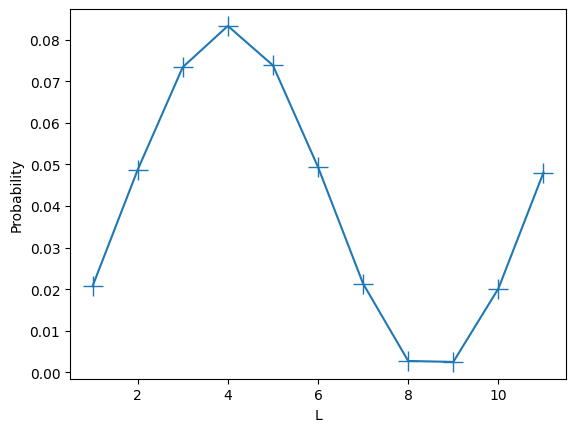

In [19]:
import matplotlib.pyplot as plt
          
largest_amp_list_dicke = [np.abs(psi.state_op.coeff_vec[0])**2 for psi in output_states_list_dicke]
largest_bitstring_dicke = [psi[0] for psi in output_states_list_dicke]

plt.plot(repeat_list_dicke, largest_amp_list_dicke, marker="+", markersize=15)
plt.xlabel("L")
plt.ylabel("Probability")

largest_bitstring_dicke

In [21]:
## save output states!

with h5py.File("OH_output_study2.h5", "w") as outf:
    for idx, psi in enumerate(output_states_list_dicke):
        outf.create_dataset(f"psi_{idx}_state_matrix", data=psi.state_matrix)
        outf.create_dataset(f"psi_{idx}_coeff_vec", data=psi.state_op.coeff_vec)

In [36]:
opt_iteration_psi = output_states_list_dicke[3]

In [61]:
n_samples_from_statevec = 10_000

sampled_state = opt_iteration_psi.sample_state(n_samples_from_statevec).cleanup().sort()
sampled_state

 897.000+0.000j |000011100111> +
 853.000+0.000j |000001101111> +
 852.000+0.000j |000010011111> +
 842.000+0.000j |000011011011> +
 836.000+0.000j |000001111110> +
 831.000+0.000j |000011101101> +
 821.000+0.000j |000010111101> +
 818.000+0.000j |000010110111> +
 817.000+0.000j |000001111011> +
 814.000+0.000j |000011011110> +
 810.000+0.000j |000011110110> +
 809.000+0.000j |000011111001>

In [73]:
sample_number = []
energy_list   = []
state_label = []
for psi_sample in sampled_state:
    sampled_eigenstate = QuantumState(psi_sample.state_matrix[0,::-1]) # need to reverse as qiskit encocdes left to right
    energy_state =f_op.expval(sampled_eigenstate)
    energy_list.append(energy_state)
    sample_number.append(psi_sample.state_op.coeff_vec[0].real)
    int_label = sampled_eigenstate.state_matrix[0].dot(1 << np.arange(psi_sample.state_matrix.shape[-1] - 1, -1, -1))
    state_label.append(int_label)

energy_list = np.array(energy_list)
state_label = np.array(state_label)
sample_number = np.array(sample_number)

re_order = np.argsort(state_label)

energy_list = energy_list[re_order]
state_label = state_label[re_order]
sample_number = sample_number[re_order]

In [79]:
sample_number

array([810., 814., 836., 809., 831., 821., 842., 817., 897., 818., 853.,
       852.])

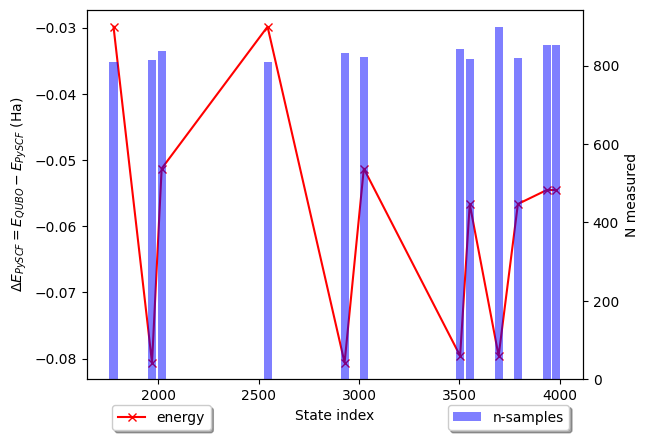

In [105]:
energy_diff = (energy_list - pyscf_soln).real



fig1=plt.figure(1)
ax=fig1.gca()
ax2=ax.twinx()

ax2.bar(state_label, sample_number, width=40, label='n-samples', color='b', alpha=0.5)
ax.plot(state_label, energy_diff, label='energy', color='r', marker='x')


ax.set_xlabel("State index")

ax2.set_ylabel("N measured")
ax.set_ylabel(r'$\Delta E_{PySCF} = E_{QUBO}-E_{PySCF}$ (Ha)')

ax.legend()
ax2.legend()

ax.legend(loc='upper center', bbox_to_anchor=(0.15, -0.05),
          fancybox=True, shadow=True, ncol=5)
ax2.legend(loc='upper center', bbox_to_anchor=(0.85, -0.05),
          fancybox=True, shadow=True, ncol=5)


plt.savefig('OH_study2.png', dpi=300)